step 1 google mount drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Step 2: Install libraries

In [ ]:

!pip install xgboost imbalanced-learn -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")


All libraries imported successfully!


Step 3: Upload and load dataset

In [ ]:

import zipfile
import pandas as pd

with zipfile.ZipFile("aug_train.csv.zip", "r") as zip_file:
    with zip_file.open("aug_train.csv") as file:
        df = pd.read_csv(file)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset Shape: (19158, 14)


,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0


Step 4: Check dataset information

In [ ]:

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTarget Distribution:")
print(df["target"].value_counts())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   enrollee_id             19158 non-null  int64  
 1   city                    19158 non-null  object 
 2   city_development_index  19158 non-null  float64
 3   gender                  14650 non-null  object 
 4   relevent_experience     19158 non-null  object 
 5   enrolled_university     18772 non-null  object 
 6   education_level         18698 non-null  object 
 7   major_discipline        16345 non-null  object 
 8   experience              19093 non-null  object 
 9   company_size            13220 non-null  object 
 10  company_type            13018 non-null  object 
 11  last_new_job            18735 non-null  object 
 12  training_hours          19158 non-null  int64  
 13  target                  19158 non-null  float64
dtypes: float64(2), in

Step 5 – Data cleaning and preprocessing

5.1 Remove unnecessary employee ID and clean experience

In [ ]:

# Create a copy of original dataset
df_clean = df.copy()

# Remove employee ID
df_clean.drop("enrollee_id", axis=1, inplace=True)

# Clean experience column
df_clean["experience"] = (
    df_clean["experience"]
    .replace({"<1": "0.5", ">20": "21.0"})
)

# Convert experience into numeric
df_clean["experience"] = pd.to_numeric(
    df_clean["experience"], errors="coerce"
)

print("Experience cleaned successfully!")
print(df_clean["experience"].head(10))


Experience cleaned successfully!
0    21.0
1    15.0
2     5.0
3     0.5
4    21.0
5    11.0
6     5.0
7    13.0
8     7.0
9    17.0
Name: experience, dtype: float64


5.2 Handle missing values

In [ ]:

# Separate numerical and categorical columns
num_cols = df_clean.select_dtypes(
    include=["int64", "float64"]
).columns

cat_cols = df_clean.select_dtypes(
    include=["object"]
).columns

# Fill numerical missing values with median
for col in num_cols:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )

# Fill categorical missing values with Missing
for col in cat_cols:
    df_clean[col] = df_clean[col].fillna("Missing")

print("Missing values handled successfully!")

print("\nRemaining missing values:")
print(df_clean.isnull().sum().sum())


Missing values handled successfully!

Remaining missing values:
0


5.3 Check cleaned dataset

In [ ]:

print("Cleaned Dataset Shape:", df_clean.shape)

print("\nData Types:")
print(df_clean.dtypes)

print("\nMissing Values:")
print(df_clean.isnull().sum())


Cleaned Dataset Shape: (19158, 13)

Data Types:
city                       object
city_development_index    float64
gender                     object
relevent_experience        object
enrolled_university        object
education_level            object
major_discipline           object
experience                float64
company_size               object
company_type               object
last_new_job               object
training_hours              int64
target                    float64
dtype: object

Missing Values:
city                      0
city_development_index    0
gender                    0
relevent_experience       0
enrolled_university       0
education_level           0
major_discipline          0
experience                0
company_size              0
company_type              0
last_new_job              0
training_hours            0
target                    0
dtype: int64


Step 6 – Encode categorical variables

In [ ]:

from sklearn.preprocessing import LabelEncoder

# Store encoders for future Flask predictions
encoders = {}

# Identify categorical columns
cat_cols = df_clean.select_dtypes(
    include=["object"]
).columns

# Apply Label Encoding
for col in cat_cols:
    le = LabelEncoder()
    df_clean[col] = le.fit_transform(
        df_clean[col].astype(str)
    )
    encoders[col] = le

print("Label Encoding completed successfully!")

print("\nEncoded Dataset:")
display(df_clean.head())

print("\nRemaining categorical columns:")
print(df_clean.select_dtypes(include=["object"]).columns.tolist())


Label Encoding completed successfully!

Encoded Dataset:


,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,5,0.920,1,0,3,0,6,21.0,8,2,0,36,1.0
1,77,0.776,1,1,3,0,6,15.0,4,6,4,47,0.0
2,64,0.624,2,1,0,0,6,5.0,8,2,6,83,0.0
3,14,0.789,2,1,1,0,1,0.5,8,6,6,52,1.0
4,50,0.767,1,0,3,2,6,21.0,4,1,3,8,0.0



Remaining categorical columns:
[]


Step 7 – Exploratory Data Analysis (EDA)

7.1 Target distribution

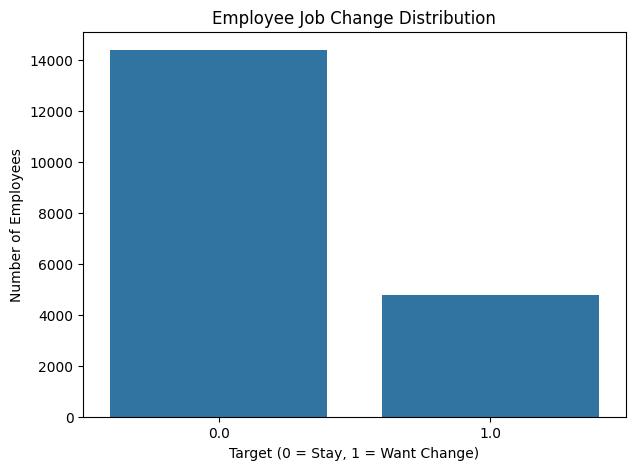

In [ ]:

plt.figure(figsize=(7, 5))

sns.countplot(
    x="target",
    data=df_clean
)

plt.title("Employee Job Change Distribution")
plt.xlabel("Target (0 = Stay, 1 = Want Change)")
plt.ylabel("Number of Employees")

plt.show()


7.2 Experience distribution

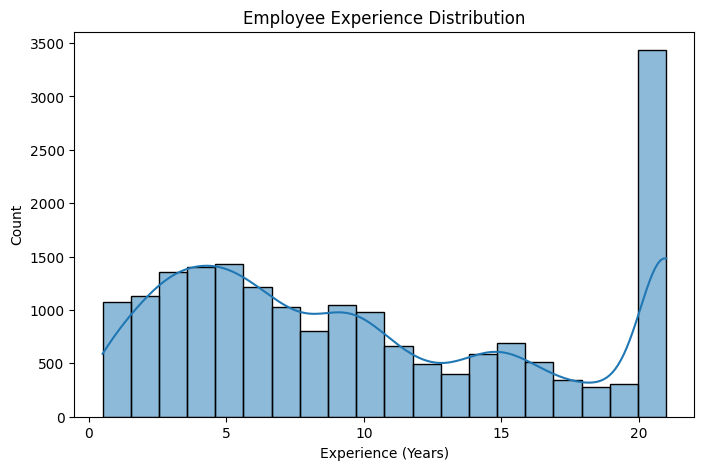

In [ ]:

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x="experience",
    bins=20,
    kde=True
)

plt.title("Employee Experience Distribution")
plt.xlabel("Experience (Years)")
plt.ylabel("Count")

plt.show()


7.3 Training hours distribution

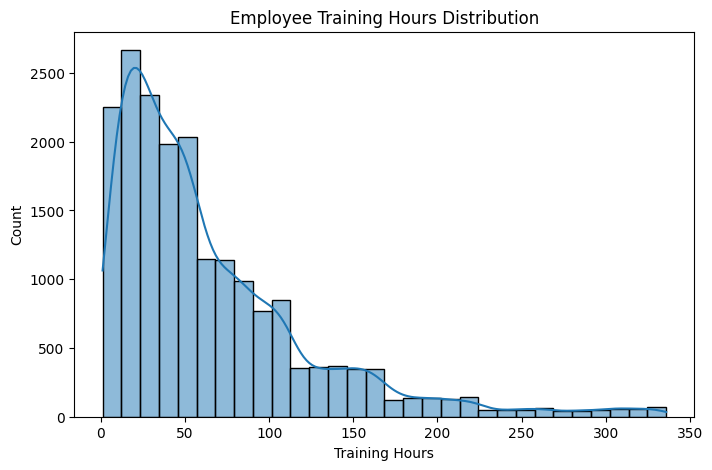

In [ ]:

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x="training_hours",
    bins=30,
    kde=True
)

plt.title("Employee Training Hours Distribution")
plt.xlabel("Training Hours")
plt.ylabel("Count")

plt.show()


7.4 Correlation heatmap

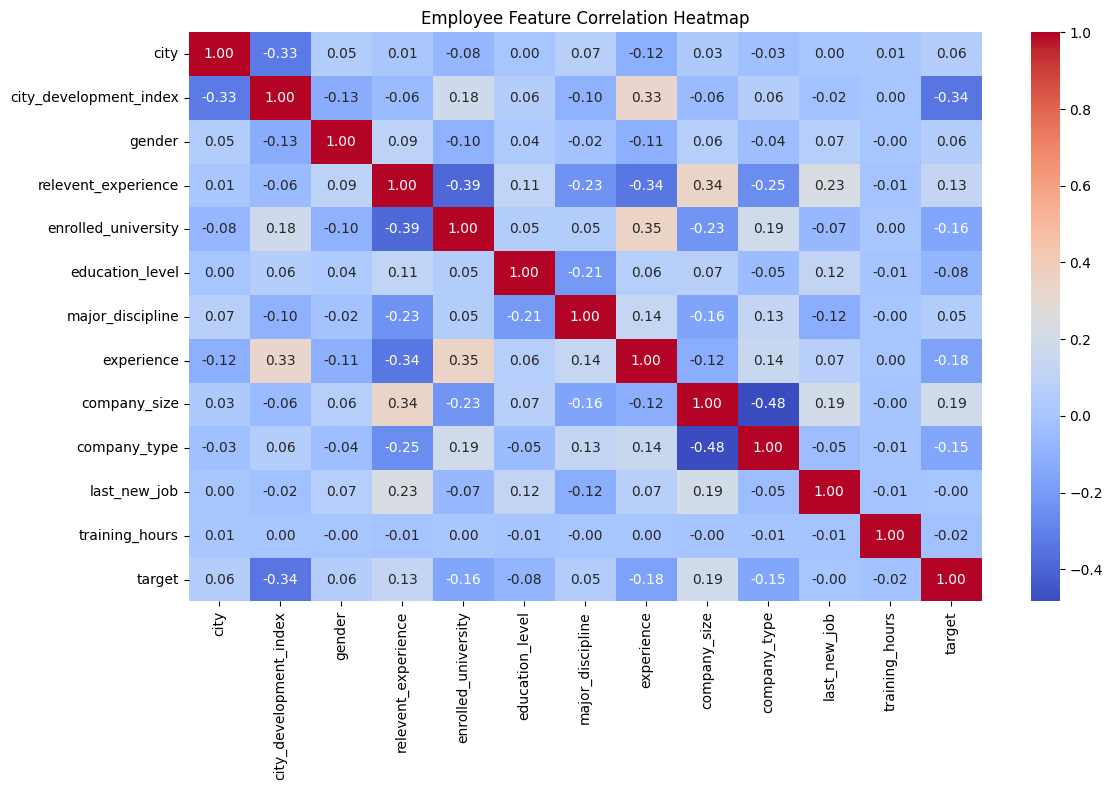

In [ ]:

plt.figure(figsize=(12, 8))

sns.heatmap(
    df_clean.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Employee Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


Step 8: Complete EDA visualizations

8.1 Education level distribution

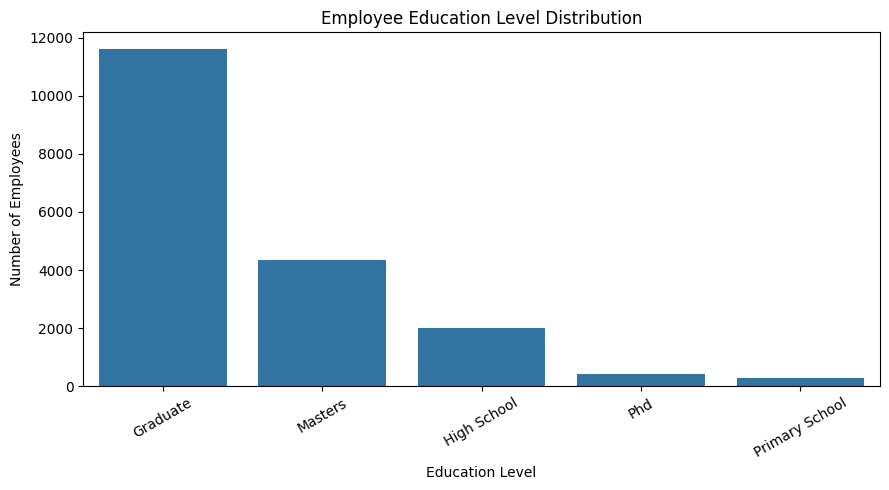

In [ ]:

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="education_level",
    order=df["education_level"].value_counts().index
)

plt.title("Employee Education Level Distribution")
plt.xlabel("Education Level")
plt.ylabel("Number of Employees")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


8.2 Gender distribution

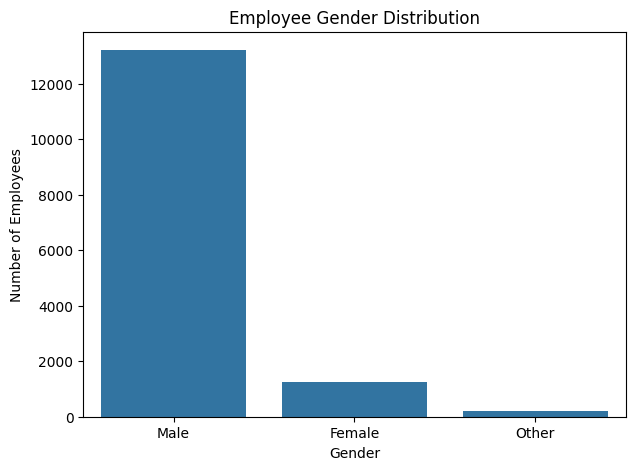

In [ ]:

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="gender")

plt.title("Employee Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Employees")
plt.show()


8.3 Company size distribution

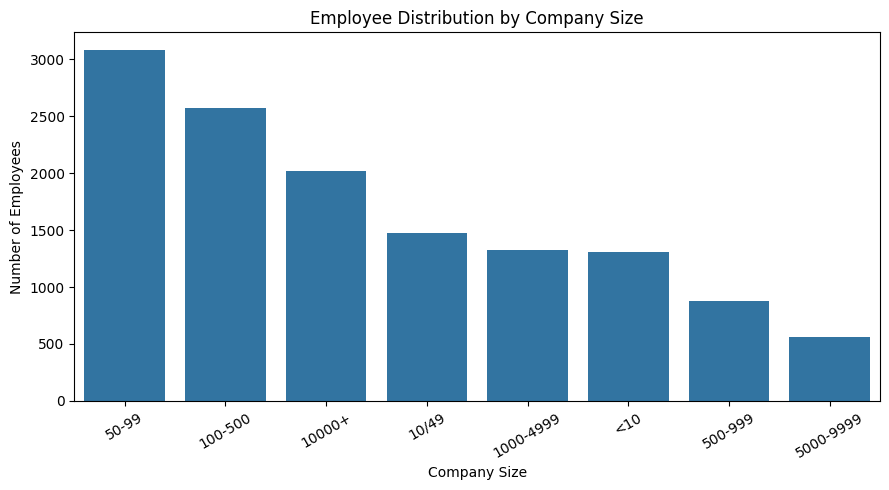

In [ ]:

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="company_size",
    order=df["company_size"].value_counts().index
)

plt.title("Employee Distribution by Company Size")
plt.xlabel("Company Size")
plt.ylabel("Number of Employees")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


8.4 Top 10 feature correlations with target

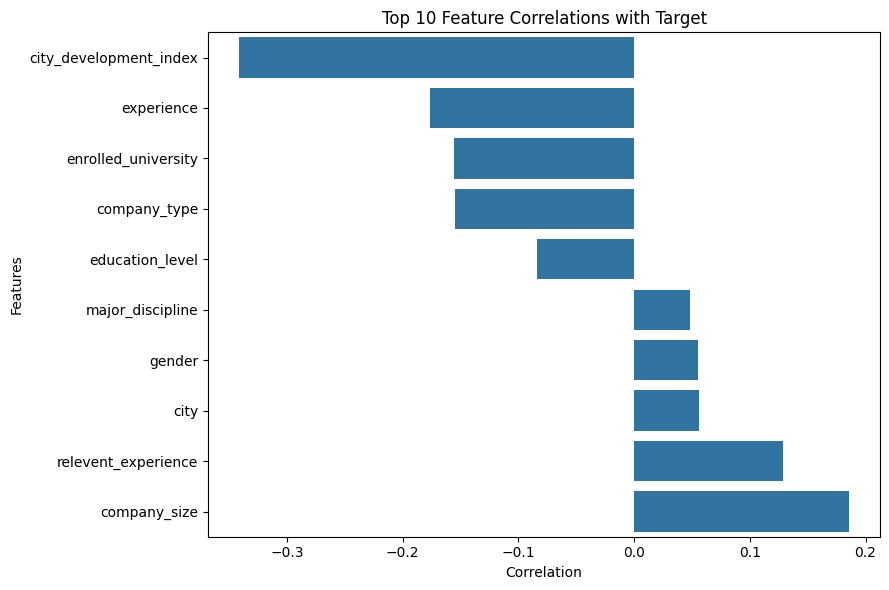

In [ ]:

correlation = df_clean.corr()["target"].drop("target")

top_features = correlation.abs().nlargest(10).index
top_corr = correlation.loc[top_features].sort_values()

plt.figure(figsize=(9, 6))

sns.barplot(
    x=top_corr.values,
    y=top_corr.index
)

plt.title("Top 10 Feature Correlations with Target")
plt.xlabel("Correlation")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


Step 9 – Train, validation and test split

9.1 Separate X and Y

In [ ]:

# Features and target
X = df_clean.drop("target", axis=1)

y = df_clean["target"].astype(int)

print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (19158, 12)
Target shape: (19158,)


9.2 Split the dataset

In [ ]:

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: 15% validation, 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)


Training data: (13410, 12)
Validation data: (2874, 12)
Testing data: (2874, 12)


9.3 Feature scaling

In [ ]:

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_val_scaled = scaler.transform(X_val)

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")
print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Testing:", X_test_scaled.shape)


Feature scaling completed!
Training: (13410, 12)
Validation: (2874, 12)
Testing: (2874, 12)


Step 10 – Apply SMOTE

In [ ]:

from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_balanced.value_counts())


Before SMOTE:
target
0    10066
1     3344
Name: count, dtype: int64

After SMOTE:
target
1    10066
0    10066
Name: count, dtype: int64


Step 11: Model Training

Step 11.1 – Import model libraries

In [ ]:

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

print("Machine Learning models imported successfully!")


Machine Learning models imported successfully!


Step 11.2 – Train Random Forest

In [ ]:

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train_balanced, y_train_balanced)

# Validation prediction
rf_pred = rf_model.predict(X_val_scaled)
rf_prob = rf_model.predict_proba(X_val_scaled)[:, 1]

print("Random Forest Training Completed!")


Random Forest Training Completed!


Step 11.3 – Train XGBoost

In [ ]:

xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Train model
xgb_model.fit(X_train_balanced, y_train_balanced)

# Validation prediction
xgb_pred = xgb_model.predict(X_val_scaled)
xgb_prob = xgb_model.predict_proba(X_val_scaled)[:, 1]

print("XGBoost Training Completed!")


XGBoost Training Completed!


Step 12 – Model evaluation

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []

models = {
    "Random Forest": (rf_pred, rf_prob),
    "XGBoost": (xgb_pred, xgb_prob)
}

for name, (pred, prob) in models.items():

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred),
        "Recall": recall_score(y_val, pred),
        "F1 Score": f1_score(y_val, pred),
        "AUC-ROC": roc_auc_score(y_val, prob)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))


,Model,Accuracy,Precision,Recall,F1 Score,AUC-ROC
0,Random Forest,0.7975,0.5722,0.7462,0.6477,0.8227
1,XGBoost,0.8097,0.6032,0.6932,0.6450,0.8214


Step 13 – Confusion matrices

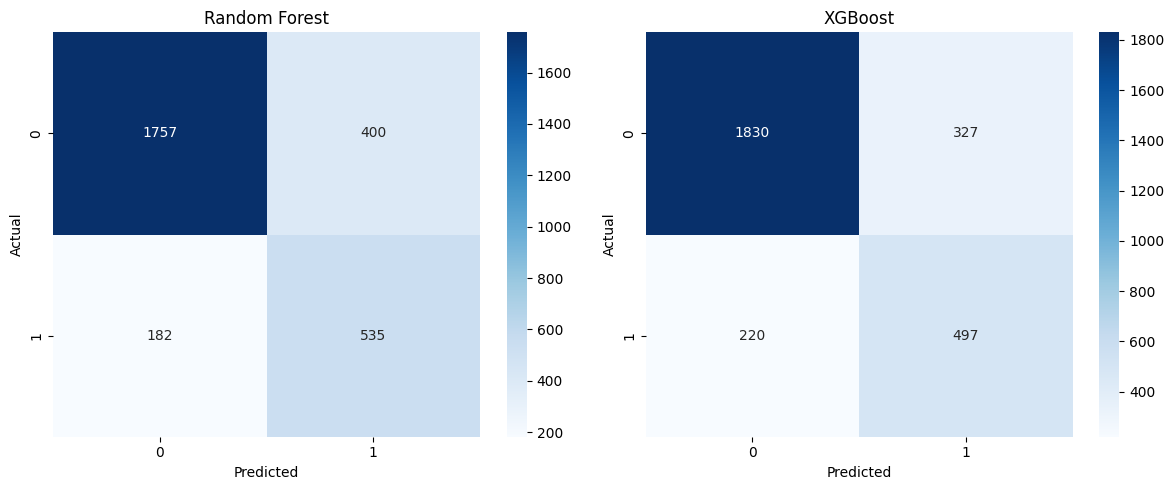

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, (pred, prob)) in zip(axes, models.items()):

    cm = confusion_matrix(y_val, pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


Step 14 – ROC curve comparison

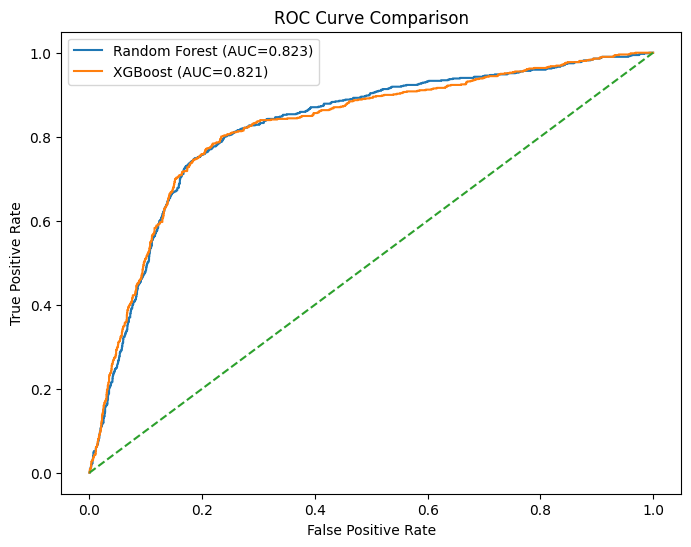

In [ ]:

from sklearn.metrics import roc_curve

plt.figure(figsize=(8, 6))

for name, (pred, prob) in models.items():

    fpr, tpr, thresholds = roc_curve(y_val, prob)
    auc = roc_auc_score(y_val, prob)

    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()


Step 15: 5-Fold Cross-Validation

15.1 Import libraries

In [ ]:

from sklearn.model_selection import StratifiedKFold, cross_validate
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# Create 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-Fold Cross-Validation Ready!")


5-Fold Cross-Validation Ready!


15.2 Evaluate Random Forest and XGBoost

In [ ]:

# Models for cross-validation
cv_models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=6,
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    )
}

cv_results = []

for name, model in cv_models.items():

    pipeline = ImbPipeline([
        ("smote", SMOTE(random_state=42)),
        ("model", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train_scaled,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "f1": "f1",
            "roc_auc": "roc_auc"
        },
        n_jobs=1
    )

    cv_results.append({
        "Model": name,
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "F1 Mean": scores["test_f1"].mean(),
        "F1 Std": scores["test_f1"].std(),
        "AUC Mean": scores["test_roc_auc"].mean(),
        "AUC Std": scores["test_roc_auc"].std()
    })

cv_df = pd.DataFrame(cv_results)

display(cv_df.round(4))


,Model,Accuracy Mean,Accuracy Std,F1 Mean,F1 Std,AUC Mean,AUC Std
0,Random Forest,0.7861,0.0090,0.6200,0.0174,0.7945,0.0158
1,XGBoost,0.7931,0.0108,0.6085,0.0216,0.7919,0.0156


Step 16 – Feature Importance Analysis

16.1 Random Forest feature importance

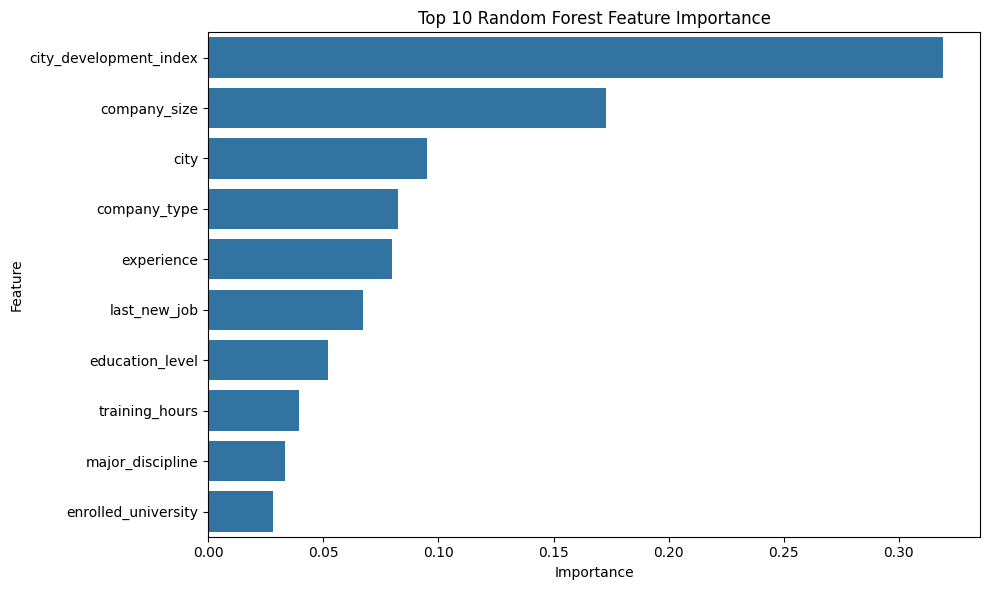

,Feature,Importance
1,city_development_index,0.319258
8,company_size,0.172755
0,city,0.095080
9,company_type,0.082560
7,experience,0.079631
10,last_new_job,0.067183
5,education_level,0.052035
11,training_hours,0.039461
6,major_discipline,0.033427
4,enrolled_university,0.028096


In [ ]:

feature_names = X.columns

rf_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

rf_importance = rf_importance.sort_values(
    by="Importance", ascending=False
).head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=rf_importance,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Random Forest Feature Importance")
plt.tight_layout()
plt.show()

display(rf_importance)


16.2 XGBoost feature importance

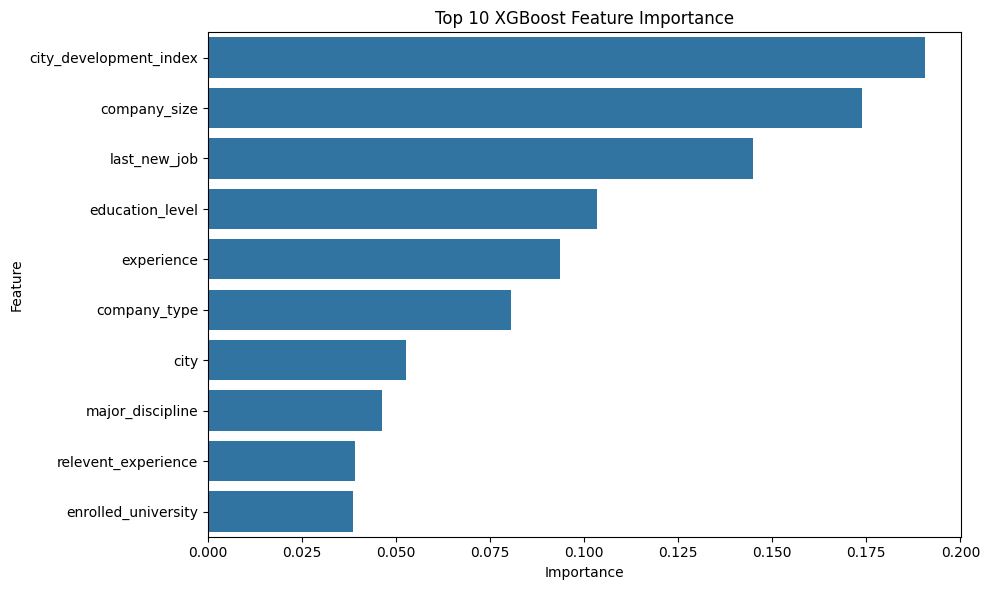

,Feature,Importance
1,city_development_index,0.190715
8,company_size,0.173832
10,last_new_job,0.144795
5,education_level,0.103458
7,experience,0.093492
9,company_type,0.080491
0,city,0.052555
6,major_discipline,0.046107
3,relevent_experience,0.039138
4,enrolled_university,0.038622


In [ ]:

xgb_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by="Importance", ascending=False
).head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=xgb_importance,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 XGBoost Feature Importance")
plt.tight_layout()
plt.show()

display(xgb_importance)


Step 17 – Learning Curves

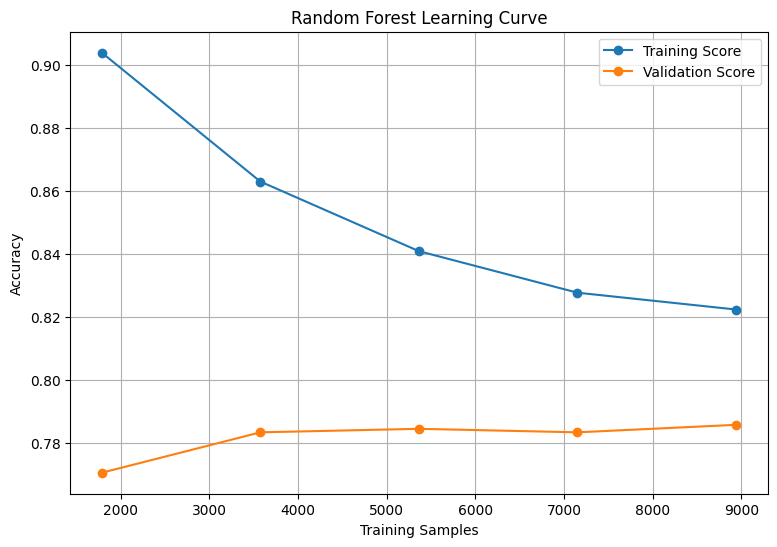

In [ ]:

from sklearn.model_selection import learning_curve

# Use Random Forest with SMOTE inside each training fold
learning_pipeline = ImbPipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ))
])

train_sizes, train_scores, val_scores = learning_curve(
    learning_pipeline,
    X_train_scaled,
    y_train,
    cv=3,
    scoring="accuracy",
    train_sizes=np.linspace(0.2, 1.0, 5),
    n_jobs=1
)

plt.figure(figsize=(9, 6))

plt.plot(
    train_sizes,
    train_scores.mean(axis=1),
    marker="o",
    label="Training Score"
)

plt.plot(
    train_sizes,
    val_scores.mean(axis=1),
    marker="o",
    label="Validation Score"
)

plt.title("Random Forest Learning Curve")
plt.xlabel("Training Samples")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()


Step 18 – Final test evaluation

In [ ]:

from sklearn.metrics import classification_report

for name, model in [
    ("Random Forest", rf_model),
    ("XGBoost", xgb_model)
]:
    predictions = model.predict(X_test_scaled)
    probabilities = model.predict_proba(X_test_scaled)[:, 1]

    print("\n", "=" * 40)
    print(name)
    print("=" * 40)

    print(classification_report(
        y_test,
        predictions,
        target_names=["Stay", "Want Change"]
    ))

    print("AUC-ROC:", round(
        roc_auc_score(y_test, probabilities), 4
    ))



Random Forest
              precision    recall  f1-score   support

        Stay       0.90      0.81      0.85      2158
 Want Change       0.56      0.72      0.63       716

    accuracy                           0.79      2874
   macro avg       0.73      0.77      0.74      2874
weighted avg       0.81      0.79      0.80      2874

AUC-ROC: 0.7983

XGBoost
              precision    recall  f1-score   support

        Stay       0.88      0.84      0.86      2158
 Want Change       0.57      0.65      0.61       716

    accuracy                           0.79      2874
   macro avg       0.72      0.74      0.73      2874
weighted avg       0.80      0.79      0.79      2874

AUC-ROC: 0.801


Step 19 – Save trained ML models

19.1 Install Joblib

In [ ]:

!pip install joblib -q

import joblib
import os

os.makedirs("models", exist_ok=True)

print("Model folder created successfully!")


Model folder created successfully!


19.2 Save Random Forest, XGBoost and preprocessing files

In [ ]:

# Save trained models
joblib.dump(rf_model, "models/random_forest.pkl")
joblib.dump(xgb_model, "models/xgboost.pkl")

# Save scaler and encoders
joblib.dump(scaler, "models/scaler.pkl")
joblib.dump(encoders, "models/encoders.pkl")

# Save feature names
joblib.dump(list(X.columns), "models/feature_names.pkl")

print("All model files saved successfully!")


All model files saved successfully!


19.3 Download model files

In [ ]:

import shutil

shutil.make_archive(
    "employee_models",
    "zip",
    "models"
)

from google.colab import files

files.download("employee_models.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Step 20 — Download the trained models

Step 1 — Check which models are available

In [ ]:
import os
import shutil
import joblib

# Check that models are trained
required = ["rf_model", "xgb_model", "scaler", "encoders", "X"]

for name in required:
    if name not in globals():
        raise ValueError(
            f"{name} is missing. Run the required training/preprocessing cell first."
        )

# Create models folder
os.makedirs("models", exist_ok=True)

# Save models and preprocessing files
joblib.dump(rf_model, "models/random_forest.pkl")
joblib.dump(xgb_model, "models/xgboost.pkl")
joblib.dump(scaler, "models/scaler.pkl")
joblib.dump(encoders, "models/encoders.pkl")
joblib.dump(list(X.columns), "models/feature_names.pkl")

# Create ZIP file
shutil.make_archive("employee_models", "zip", "models")

print("All models saved successfully!")

All models saved successfully!


20.2 Download ZIP file

In [ ]:
from google.colab import files

files.download("employee_models.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Step 21 — Create a Flask web application

Step 21 — Create a Flask web application

In [ ]:
import os

os.makedirs("templates", exist_ok=True)
os.makedirs("static", exist_ok=True)

21.2 Create app.py

In [ ]:
%%writefile app.py

from flask import Flask, render_template, request
import pandas as pd
import joblib

app = Flask(__name__)

# Load saved files
rf_model = joblib.load("models/random_forest.pkl")
scaler = joblib.load("models/scaler.pkl")
encoders = joblib.load("models/encoders.pkl")
feature_names = joblib.load("models/feature_names.pkl")

numeric_fields = [
    "city_development_index",
    "experience",
    "training_hours"
]

@app.route("/")
def home():
    categories = {
        col: list(encoders[col].classes_)
        for col in encoders
    }
    return render_template(
        "index.html",
        categories=categories,
        numeric_fields=numeric_fields
    )

@app.route("/predict", methods=["POST"])
def predict():
    try:
        data = {}

        for col in feature_names:
            value = request.form[col]

            if col in numeric_fields:
                data[col] = float(value)
            else:
                data[col] = encoders[col].transform([value])[0]

        input_df = pd.DataFrame([data], columns=feature_names)
        input_scaled = scaler.transform(input_df)

        prediction = rf_model.predict(input_scaled)[0]

        if prediction == 1:
            result = "Likely looking for a job change"
        else:
            result = "Not currently looking for a job change"

        return render_template("result.html", result=result)

    except Exception as e:
        return f"Prediction error: {e}", 400

if __name__ == "__main__":
    app.run(debug=True)

Writing app.py


21.3 Create the input page

In [ ]:
%%writefile templates/index.html

<!DOCTYPE html>
<html>
<head>
    <title>Employee Prediction</title>
</head>
<body>
    <h1>Employee Job Change Prediction</h1>

    <form action="/predict" method="POST">

        {% for field, options in categories.items() %}
            <label>{{ field }}</label>
            <select name="{{ field }}" required>
                {% for option in options %}
                    <option value="{{ option }}">{{ option }}</option>
                {% endfor %}
            </select>
            <br><br>
        {% endfor %}

        {% for field in numeric_fields %}
            <label>{{ field }}</label>
            <input type="number" step="any"
                   name="{{ field }}" required>
            <br><br>
        {% endfor %}

        <button type="submit">Predict</button>

    </form>
</body>
</html>

Writing templates/index.html


21.4 Create the result page

In [ ]:
%%writefile templates/result.html

<!DOCTYPE html>
<html>
<head>
    <title>Prediction Result</title>
</head>
<body>
    <h1>Prediction Result</h1>

    <h2>{{ result }}</h2>

    <a href="/">Go Back</a>
</body>
</html>

Writing templates/result.html


21.5 Create requirements.txt

In [ ]:
%%writefile requirements.txt

flask
pandas
numpy
scikit-learn
xgboost
imbalanced-learn
joblib

Writing requirements.txt


21.6 Create the final project ZIP

In [ ]:
import zipfile
import os

# Define the files and directories to include in the project ZIP
project_files = [
    "app.py",
    "requirements.txt"
]
project_dirs = [
    "templates",
    "static",
    "models"
]

zip_filename = "Employee_Promotion_Prediction_Project.zip"

with zipfile.ZipFile(zip_filename, "w", zipfile.ZIP_DEFLATED) as zipf:
    # Add individual files
    for file in project_files:
        if os.path.exists(file):
            zipf.write(file)
            print(f"Added file: {file}")

    # Add directories recursively
    for directory in project_dirs:
        if os.path.exists(directory):
            for root, dirs, files in os.walk(directory):
                for file in files:
                    file_path = os.path.join(root, file)
                    zipf.write(file_path)
            print(f"Added directory: {directory}")

print(f"\nProject ZIP '{zip_filename}' created successfully without self-recursion!")

Added file: app.py
Added file: requirements.txt
Added directory: templates
Added directory: static
Added directory: models

Project ZIP 'Employee_Promotion_Prediction_Project.zip' created successfully without self-recursion!


Step 21.7 — Check your project files

In [ ]:
import os

for folder in ["templates", "static", "models"]:
    print(f"\n{folder} folder:")
    if os.path.exists(folder):
        for root, dirs, files in os.walk(folder):
            for file in files:
                print("  ", os.path.join(root, file))
    else:
        print("Folder not found")


templates folder:
   templates/result.html
   templates/index.html

static folder:

models folder:
   models/encoders.pkl
   models/feature_names.pkl
   models/scaler.pkl
   models/random_forest.pkl
   models/xgboost.pkl


Step 21.8 — Verify the final ZIP contents.

In [ ]:
import zipfile

zip_filename = "Employee_Promotion_Prediction_Project.zip"

with zipfile.ZipFile(zip_filename, "r") as zip_ref:
    print("Files inside final project ZIP:\n")

    for file in zip_ref.namelist():
        print(file)

Files inside final project ZIP:

app.py
requirements.txt
templates/result.html
templates/index.html
models/encoders.pkl
models/feature_names.pkl
models/scaler.pkl
models/random_forest.pkl
models/xgboost.pkl


Step 21.9 — Download your project ZIP

In [ ]:
from google.colab import files

files.download("Employee_Promotion_Prediction_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Step 21.10 — Install Flask and prepare the website.

In [ ]:
!pip install flask -q

import flask

print("Flask installed successfully!")
print("Flask version:", flask.__version__)

Flask installed successfully!
Flask version: 3.1.3


Step 21.11 — Check saved model files

In [ ]:
import os

print("Model files:")

if os.path.exists("models"):
    for file in os.listdir("models"):
        print(file)
else:
    print("Models folder not found")

Model files:
encoders.pkl
feature_names.pkl
scaler.pkl
random_forest.pkl
xgboost.pkl


Step 21.12 — Check whether your Flask project is ready

In [ ]:
import os

required_files = [
    "app.py",
    "requirements.txt",
    "models/random_forest.pkl",
    "models/scaler.pkl",
    "models/encoders.pkl",
    "models/feature_names.pkl",
    "templates/index.html",
    "templates/result.html"
]

for file in required_files:
    status = "Available" if os.path.exists(file) else "Missing"
    print(file, ":", status)

app.py : Available
requirements.txt : Available
models/random_forest.pkl : Available
models/scaler.pkl : Available
models/encoders.pkl : Available
models/feature_names.pkl : Available
templates/index.html : Available
templates/result.html : Available


Step 21.13 — Start the Flask website

In [ ]:
import os

print("app.py:", os.path.exists("app.py"))
print("Model folder:", os.path.exists("models"))
print("Input page:", os.path.exists("templates/index.html"))
print("Result page:", os.path.exists("templates/result.html"))

app.py: True
Model folder: True
Input page: True
Result page: True


In [ ]:
!pip install pyngrok -q

Step 21.14 — Check model files

In [ ]:
import os

print("Files inside models folder:")

if os.path.exists("models"):
    for file in os.listdir("models"):
        print("✔", file)

Files inside models folder:
✔ encoders.pkl
✔ feature_names.pkl
✔ scaler.pkl
✔ random_forest.pkl
✔ xgboost.pkl


Step 21.14 — Verify saved ML models.

In [ ]:
import os

model_files = [
    "random_forest.pkl",
    "xgboost.pkl",
    "scaler.pkl",
    "encoders.pkl",
    "feature_names.pkl"
]

for file in model_files:
    path = os.path.join("models", file)

    if os.path.exists(path):
        print("✅ Available:", file)
    else:
        print("❌ Missing:", file)

✅ Available: random_forest.pkl
✅ Available: xgboost.pkl
✅ Available: scaler.pkl
✅ Available: encoders.pkl
✅ Available: feature_names.pkl


Step 21.15 — Load and test your saved models

In [ ]:
import os
import joblib

model_path = "models"

required_files = [
    "random_forest.pkl",
    "xgboost.pkl",
    "scaler.pkl",
    "encoders.pkl",
    "feature_names.pkl"
]

missing = [
    f for f in required_files
    if not os.path.exists(os.path.join(model_path, f))
]

if missing:
    print("Missing files:", missing)
    print("We need to save or retrain the models first.")
else:
    rf_model = joblib.load("models/random_forest.pkl")
    scaler = joblib.load("models/scaler.pkl")
    encoders = joblib.load("models/encoders.pkl")
    feature_names = joblib.load("models/feature_names.pkl")

    print("All required model files loaded successfully!")

All required model files loaded successfully!


Step 21.16 — Launch your Flask website

In [ ]:
!pip install flask -q

from flask import Flask
print("Flask is ready!")

Flask is ready!


Step 21.16 — Run your Flask website

In [ ]:
import os
import joblib
import threading
from IPython.display import display, HTML
from google.colab.output import eval_js

# Check model files
required_files = [
    "random_forest.pkl",
    "xgboost.pkl",
    "scaler.pkl",
    "encoders.pkl",
    "feature_names.pkl"
]

missing = [
    f for f in required_files
    if not os.path.exists("models/" + f)
]

if missing:
    print("Cannot launch website. Missing model files:", missing)

else:
    # Test loading saved files
    for f in required_files:
        joblib.load("models/" + f)

    print("All model files loaded successfully!")

    # Import Flask application
    from app import app

    # Start Flask server
    server = threading.Thread(
        target=lambda: app.run(
            host="0.0.0.0",
            port=5000,
            debug=False,
            use_reloader=False
        ),
        daemon=True
    )
    server.start()

    # Open website
    url = eval_js("google.colab.kernel.proxyPort(5000)")
    display(HTML(f'<a href="{url}" target="_blank">Open Employee Prediction Website</a>'))

All model files loaded successfully!
 * Serving Flask app 'app'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:5000
 * Running on http://172.28.0.12:5000
INFO:werkzeug:Press CTRL+C to quit


Step 21.19 — Improve website design

21.19.1 — Design the main prediction page

In [ ]:

%%writefile templates/index.html

<!DOCTYPE html>
<html>
<head>
    <title>Employee Job Change Prediction</title>
    <meta name="viewport" content="width=device-width, initial-scale=1">

    <style>
        body {
            font-family: Arial, sans-serif;
            background: #f1f5f9;
            margin: 0;
            padding: 30px 15px;
        }

        .container {
            max-width: 650px;
            margin: auto;
            background: white;
            padding: 30px;
            border-radius: 15px;
            box-shadow: 0 5px 20px #00000015;
        }

        h1 {
            text-align: center;
            color: #243b63;
        }

        p {
            text-align: center;
            color: #64748b;
        }

        label {
            display: block;
            margin-top: 17px;
            font-weight: bold;
            color: #334155;
        }

        input, select {
            width: 100%;
            padding: 12px;
            margin-top: 7px;
            border: 1px solid #cbd5e1;
            border-radius: 7px;
            box-sizing: border-box;
            font-size: 15px;
        }

        button {
            width: 100%;
            margin-top: 25px;
            padding: 14px;
            background: #3156a3;
            color: white;
            border: none;
            border-radius: 8px;
            font-size: 17px;
            cursor: pointer;
        }

        button:hover {
            background: #243b63;
        }

        .footer {
            text-align: center;
            margin-top: 20px;
            font-size: 12px;
        }
    </style>
</head>

<body>
    <div class="container">

        <h1>Employee Job Change Prediction</h1>

        <p>Machine Learning Based Prediction System</p>

        <form action="/predict" method="POST">

            {% for field, options in categories.items() %}
                <label>{{ field.replace('_', ' ').title() }}</label>

                <select name="{{ field }}" required>
                    {% for option in options %}
                        <option value="{{ option }}">{{ option }}</option>
                    {% endfor %}
                </select>
            {% endfor %}

            {% for field in numeric_fields %}
                <label>{{ field.replace('_', ' ').title() }}</label>

                <input type="number"
                       step="any"
                       name="{{ field }}"
                       required>
            {% endfor %}

            <button type="submit">Predict Job Change</button>

        </form>

        <div class="footer">
            Employee Analytics | Machine Learning Project
        </div>

    </div>
</body>
</html>


Overwriting templates/index.html


21.19.2 — Design the prediction result page

In [ ]:

%%writefile templates/result.html

<!DOCTYPE html>
<html>
<head>
    <title>Prediction Result</title>

    <style>
        body {
            font-family: Arial, sans-serif;
            background: #f1f5f9;
            text-align: center;
            padding: 60px 15px;
        }

        .card {
            max-width: 500px;
            margin: auto;
            padding: 40px 25px;
            background: white;
            border-radius: 15px;
            box-shadow: 0 5px 20px #00000015;
        }

        h1 {
            color: #243b63;
        }

        h2 {
            color: #16865b;
            margin: 30px 0;
        }

        a {
            display: inline-block;
            padding: 12px 25px;
            background: #3156a3;
            color: white;
            text-decoration: none;
            border-radius: 8px;
        }
    </style>
</head>

<body>
    <div class="card">

        <h1>Prediction Result</h1>

        <h2>{{ result }}</h2>

        <a href="/">Try Again</a>

    </div>
</body>
</html>


Overwriting templates/result.html


Step 1 — Correct data preprocessing

In [ ]:

# STEP 1: Leakage-safe data preprocessing

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from imblearn.over_sampling import SMOTE

# Keep the original dataset unchanged
data = df.copy()

# Remove ID column
data = data.drop(columns=["enrollee_id"])

# Convert experience into numeric values
data["experience"] = data["experience"].replace({
    "<1": "0.5",
    ">20": "21"
})
data["experience"] = pd.to_numeric(
    data["experience"], errors="coerce"
)

# Separate input features and target
X = data.drop(columns=["target"])
y = data["target"].astype(int)

# Split BEFORE fitting preprocessing
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30,
    random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50,
    random_state=42, stratify=y_temp
)

# Identify numerical and categorical columns
num_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

cat_cols = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

# Preprocessing pipelines
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, num_cols),
    ("cat", categorical_pipeline, cat_cols)
])

# Fit ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Apply SMOTE ONLY to training data
smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_processed, y_train
)

print("Preprocessing completed successfully!")
print("Training data:", X_train_balanced.shape)
print("Validation data:", X_val_processed.shape)
print("Testing data:", X_test_processed.shape)
print("Training classes after SMOTE:")
print(y_train_balanced.value_counts())


Preprocessing completed successfully!
Training data: (20132, 164)
Validation data: (2874, 164)
Testing data: (2874, 164)
Training classes after SMOTE:
target
1    10066
0    10066
Name: count, dtype: int64


Step 2 — Retrain Random Forest and XGBoost

Step 2.1 — Train both models

In [ ]:

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_balanced, y_train_balanced)

# Train XGBoost
xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_balanced, y_train_balanced)

print("Random Forest trained successfully!")
print("XGBoost trained successfully!")


Random Forest trained successfully!
XGBoost trained successfully!


Step 2.2 — Validate both models

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Predictions
rf_pred = rf_model.predict(X_val_processed)
xgb_pred = xgb_model.predict(X_val_processed)

rf_prob = rf_model.predict_proba(X_val_processed)[:, 1]
xgb_prob = xgb_model.predict_proba(X_val_processed)[:, 1]

# Evaluation function
def evaluate_model(name, y_true, predictions, probabilities):
    print("\n", name)
    print("Accuracy:", accuracy_score(y_true, predictions))
    print("Precision:", precision_score(y_true, predictions))
    print("Recall:", recall_score(y_true, predictions))
    print("F1 Score:", f1_score(y_true, predictions))
    print("ROC-AUC:", roc_auc_score(y_true, probabilities))

evaluate_model("Random Forest", y_val, rf_pred, rf_prob)
evaluate_model("XGBoost", y_val, xgb_pred, xgb_prob)



 Random Forest
Accuracy: 0.7651356993736952
Precision: 0.5230263157894737
Recall: 0.6652719665271967
F1 Score: 0.585635359116022
ROC-AUC: 0.7941359228071945

 XGBoost
Accuracy: 0.7891440501043842
Precision: 0.5694618272841051
Recall: 0.6345885634588564
F1 Score: 0.600263852242744
ROC-AUC: 0.8042172706164419


Step 3 — Compare Both Models.

Step 3.1 — Model comparison table

In [ ]:

import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "Accuracy": [
        accuracy_score(y_val, rf_pred),
        accuracy_score(y_val, xgb_pred)
    ],
    "Precision": [
        precision_score(y_val, rf_pred),
        precision_score(y_val, xgb_pred)
    ],
    "Recall": [
        recall_score(y_val, rf_pred),
        recall_score(y_val, xgb_pred)
    ],
    "F1 Score": [
        f1_score(y_val, rf_pred),
        f1_score(y_val, xgb_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_val, rf_prob),
        roc_auc_score(y_val, xgb_prob)
    ]
})

display(comparison.round(4))


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.7651,0.5230,0.6653,0.5856,0.7941
1,XGBoost,0.7891,0.5695,0.6346,0.6003,0.8042


Step 3.2 — Visual comparison

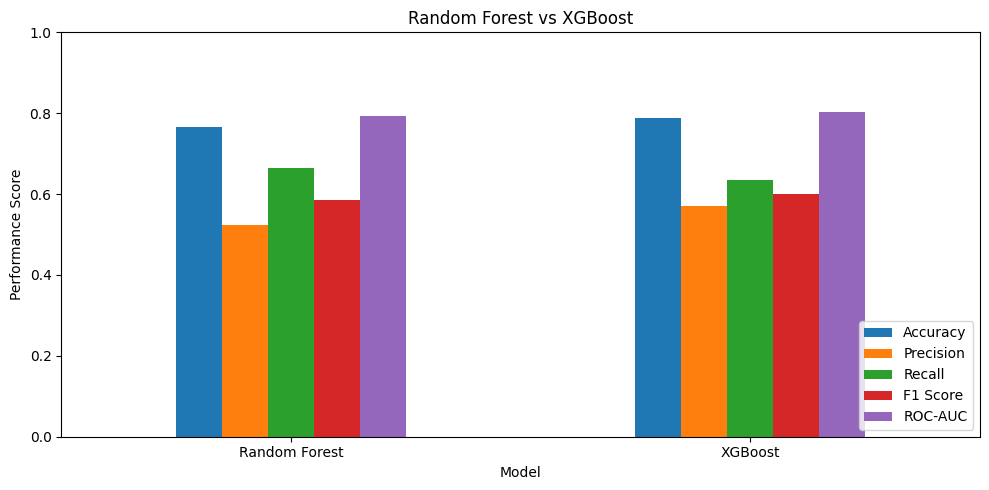

In [ ]:

import matplotlib.pyplot as plt

comparison.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Random Forest vs XGBoost")
plt.ylabel("Performance Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


Step 4: Evaluate both models on test data

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, accuracy_score

# Random Forest test predictions
rf_test_pred = rf_model.predict(X_test_processed)
rf_test_prob = rf_model.predict_proba(X_test_processed)[:, 1]

# XGBoost test predictions
xgb_test_pred = xgb_model.predict(X_test_processed)
xgb_test_prob = xgb_model.predict_proba(X_test_processed)[:, 1]

print("RANDOM FOREST - FINAL TEST RESULTS")
print(classification_report(y_test, rf_test_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_test_prob))

print("\nXGBOOST - FINAL TEST RESULTS")
print(classification_report(y_test, xgb_test_pred))
print("ROC-AUC:", roc_auc_score(y_test, xgb_test_prob))

RANDOM FOREST - FINAL TEST RESULTS
              precision    recall  f1-score   support

           0       0.88      0.78      0.83      2158
           1       0.51      0.68      0.58       716

    accuracy                           0.76      2874
   macro avg       0.69      0.73      0.71      2874
weighted avg       0.79      0.76      0.77      2874

ROC-AUC: 0.7785008750084135

XGBOOST - FINAL TEST RESULTS
              precision    recall  f1-score   support

           0       0.86      0.82      0.84      2158
           1       0.53      0.61      0.56       716

    accuracy                           0.77      2874
   macro avg       0.69      0.71      0.70      2874
weighted avg       0.78      0.77      0.77      2874

ROC-AUC: 0.7797884705991995


Step 5: Confusion Matrix

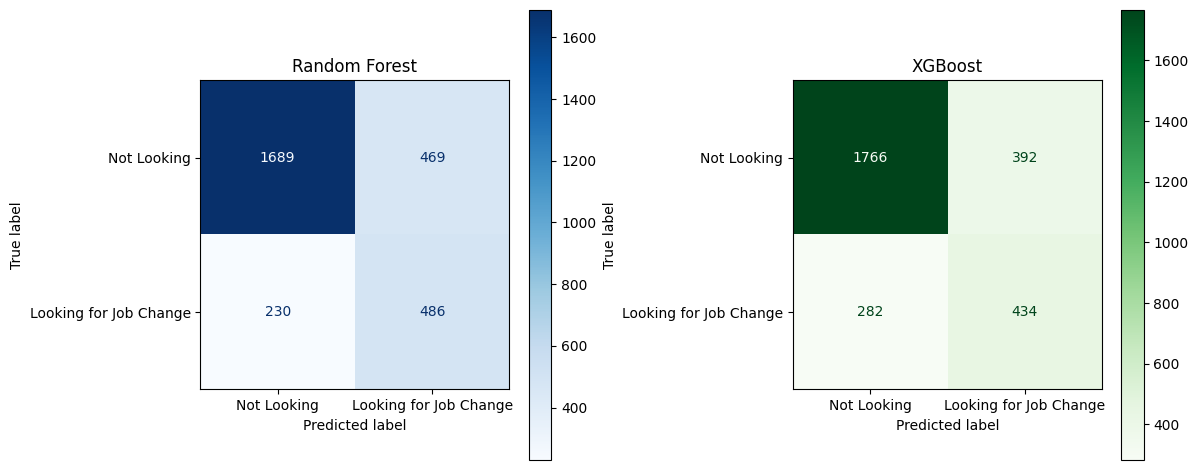

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Random Forest
ConfusionMatrixDisplay.from_predictions(
    y_test, rf_test_pred,
    display_labels=["Not Looking", "Looking for Job Change"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Random Forest")

# XGBoost
ConfusionMatrixDisplay.from_predictions(
    y_test, xgb_test_pred,
    display_labels=["Not Looking", "Looking for Job Change"],
    cmap="Greens",
    ax=axes[1]
)
axes[1].set_title("XGBoost")

plt.tight_layout()
plt.show()

Step 6: Save the models

In [ ]:
import joblib
import os

# Create a folder for saved models
os.makedirs("saved_models", exist_ok=True)

# Save preprocessing object
joblib.dump(preprocessor, "saved_models/preprocessor.pkl")

# Save Random Forest model
joblib.dump(rf_model, "saved_models/random_forest.pkl")

# Save XGBoost model
joblib.dump(xgb_model, "saved_models/xgboost.pkl")

# Save original input column names
joblib.dump(list(X_train.columns), "saved_models/feature_names.pkl")

print("All models and preprocessing files saved successfully!")

All models and preprocessing files saved successfully!


Step 6.1: Check saved files

In [ ]:
print(os.listdir("saved_models"))

['feature_names.pkl', 'random_forest.pkl', 'xgboost.pkl', 'preprocessor.pkl']


Step 7: Download the saved models

In [ ]:
import shutil
from google.colab import files

# Create one ZIP file containing all saved models
shutil.make_archive("saved_models", "zip", "saved_models")

# Download ZIP file
files.download("saved_models.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Step 8: Update your Flask project files
1.